# Circadian Cosinor Fit of the Log2 Defense Score

Updated version of `Local_analysis/Followup_analyses_after_Luke_talk/Immunity_and_defense_score/immunity_score_vs_circadian_rhythm.ipynb`.

Changes from the original:
- **Transcriptome:** plates 1–5 instead of plates 1–4. Plate 5 re-preps replace the samples they were redone for, the lower-read transcriptome of any other duplicated sample is dropped, and libraries with < 250,000 total reads are removed (as in the other notebooks in this folder).
- **Defense genes:** the 148-gene plates 1–5 list (`load_correlated_genes_union_GO_and_FLG_plates_1_to_5.csv`) instead of the 199-gene plates 1–4 list.
- **Defense score:** the **log2** score from `defense_score_variants.ipynb`: each defense gene on log2(TPM + 1), z-scored across all samples, then averaged. The original TPM score (mean z of TPM) is fitted alongside for comparison.
- **Both circadian experiments** are fitted: plates 1–4 only had Circadian Experiment 1, and plates 1–5 add Circadian Experiment 2.

**Cosinor fit** (as in the original): a single-component cosinor with a 24 h period (`CosinorPy.cosinor1.fit_group`) on hours since the first sampling of each experiment. `acrophase[h]` is the peak time in hours since the start, also shown as clock time. The fitted curves come from the equivalent least-squares fit `score ~ cos(2πt/24) + sin(2πt/24)`, which also gives the MESOR (rhythm-adjusted mean) and the R².

The second part repeats the original's defense score vs bacterial load (`ham16s`) panels for the circadian samples, with the log2 score.

In [1]:
import contextlib
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from scipy.stats import zscore, pearsonr, spearmanr
from CosinorPy import cosinor1

###Define Thresholds
period_hours = 24
min_total_reads = 250_000
experiments = ["Circadian Experiment 1", "Circadian Experiment 2"]

In [2]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()
metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)
metadata["Date and Time"] = pd.to_datetime(metadata["date"] + " " + metadata["time"], format="%m/%d/%y %H:%M")

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]
print("Transcriptomes after removing replicates:", len(trimmed_metadata))

defense_gene_list = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/load_correlated_genes_union_GO_and_FLG_plates_1_to_5.csv"
)
defense_expression = trimmed_transcriptome.loc[:, trimmed_transcriptome.columns.isin(defense_gene_list["gene"])]
# Log2 score (new) and TPM score (original), both z-scored across all samples
trimmed_metadata["Log2 Defense Score"] = np.log2(defense_expression + 1).apply(zscore).mean(axis=1)
trimmed_metadata["TPM Defense Score"] = defense_expression.apply(zscore).sum(axis=1) / len(defense_gene_list)
print(f"Defense genes: {defense_expression.shape[1]}; Spearman log2 vs TPM score: "
      f"{spearmanr(trimmed_metadata['Log2 Defense Score'], trimmed_metadata['TPM Defense Score'])[0]:.2f}")

load_table = pd.read_csv("/Users/michael/Data/Luke_terrace_experiment/Microbiome/lic2024_ham_16S_ITS.csv", index_col=0)
trimmed_metadata["ham16s"] = trimmed_metadata["sampID"].map(load_table["ham16s"])

Dropped 6 transcriptomes with < 250,000 total reads
Transcriptomes after removing replicates: 426
Defense genes: 148; Spearman log2 vs TPM score: 0.99


In [3]:
circadian = trimmed_metadata.loc[trimmed_metadata["Experiment Type"].isin(experiments)].copy()
experiment_start = circadian.groupby("Experiment Type")["Date and Time"].transform("min")
circadian["Time Since Start"] = (circadian["Date and Time"] - experiment_start) / pd.Timedelta(hours=1)
start_times = circadian.groupby("Experiment Type")["Date and Time"].min()
for experiment in experiments:
    part = circadian.loc[circadian["Experiment Type"] == experiment]
    print(f"{experiment}: {len(part)} plants, start {start_times[experiment]:%d %b %Y %H:%M}, "
          f"hours since start {sorted(part['Time Since Start'].unique())}")
circadian.groupby(["Experiment Type", "Time Since Start"]).size().unstack(0)

Circadian Experiment 1: 104 plants, start 09 Feb 2024 20:00, hours since start [np.float64(0.0), np.float64(4.0), np.float64(8.0), np.float64(12.0), np.float64(16.0), np.float64(20.0), np.float64(24.0), np.float64(28.0), np.float64(32.0), np.float64(36.0), np.float64(40.0), np.float64(44.0), np.float64(48.0)]
Circadian Experiment 2: 99 plants, start 01 Mar 2024 20:00, hours since start [np.float64(0.0), np.float64(4.0), np.float64(8.0), np.float64(12.0), np.float64(16.0), np.float64(20.0), np.float64(24.0), np.float64(28.0), np.float64(32.0), np.float64(36.0), np.float64(40.0), np.float64(44.0), np.float64(48.0)]


Experiment Type,Circadian Experiment 1,Circadian Experiment 2
Time Since Start,,
0.0,8,7
4.0,8,8
8.0,8,8
12.0,8,8
16.0,8,8
20.0,8,8
24.0,8,8
28.0,8,4
32.0,8,8


## Cosinor fits

One fit per experiment and score, with a 24 h period.

In [4]:
def ols_cosinor(df):
    """score ~ cos + sin; gives the MESOR, R² and a smooth fitted curve."""
    design = df.assign(c=np.cos(2 * np.pi * df["x"] / period_hours), s=np.sin(2 * np.pi * df["x"] / period_hours))
    fit = smf.ols("y ~ c + s", data=design).fit()
    grid = np.linspace(df["x"].min(), df["x"].max(), 300)
    curve = fit.params["Intercept"] + fit.params["c"] * np.cos(2 * np.pi * grid / period_hours) + fit.params["s"] * np.sin(2 * np.pi * grid / period_hours)
    return fit, grid, curve


cosinor_rows = []
curves = {}
for score in ["Log2 Defense Score", "TPM Defense Score"]:
    for experiment in experiments:
        part = circadian.loc[circadian["Experiment Type"] == experiment]
        df = pd.DataFrame({"x": part["Time Since Start"], "y": part[score], "test": f"{experiment} | {score}"})
        with contextlib.redirect_stdout(io.StringIO()):
            result = cosinor1.fit_group(df, period=[period_hours], plot_on=False).iloc[0]
        fit, grid, curve = ols_cosinor(df)
        curves[(score, experiment)] = (grid, curve)
        peak_clock = (start_times[experiment] + pd.Timedelta(hours=float(result["acrophase[h]"]) % period_hours)).strftime("%H:%M")
        cosinor_rows.append(
            {
                "score": score,
                "experiment": experiment,
                "n": len(df),
                "p": result["p"],
                "amplitude": result["amplitude"],
                "CI(amplitude)": result["CI(amplitude)"],
                "acrophase[h]": result["acrophase[h]"],
                "peak (clock time)": peak_clock,
                "MESOR": fit.params["Intercept"],
                "R²": fit.rsquared,
            }
        )
cosinor_results = pd.DataFrame(cosinor_rows)
cosinor_results.to_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/defense_score_circadian_cosinor_log2.csv", index=False
)
cosinor_results

,score,experiment,n,p,amplitude,CI(amplitude),acrophase[h],peak (clock time),MESOR,R²
0,Log2 Defense Score,Circadian Experiment 1,104,0.002970,0.201645,"[0.0888499947780955, 0.3144402402668562]",2.476394,22:28,-0.150794,0.108839
1,Log2 Defense Score,Circadian Experiment 2,99,0.000176,0.285055,"[0.15611805271576146, 0.4139923502657052]",2.309861,22:18,-0.044293,0.164838
2,TPM Defense Score,Circadian Experiment 1,104,0.003782,0.163892,"[0.07014675235493831, 0.25763676171521444]",2.324760,22:19,-0.180613,0.104564
3,TPM Defense Score,Circadian Experiment 2,99,0.000055,0.278470,"[0.1609775153582008, 0.3959619454091172]",2.268690,22:16,-0.044151,0.184897


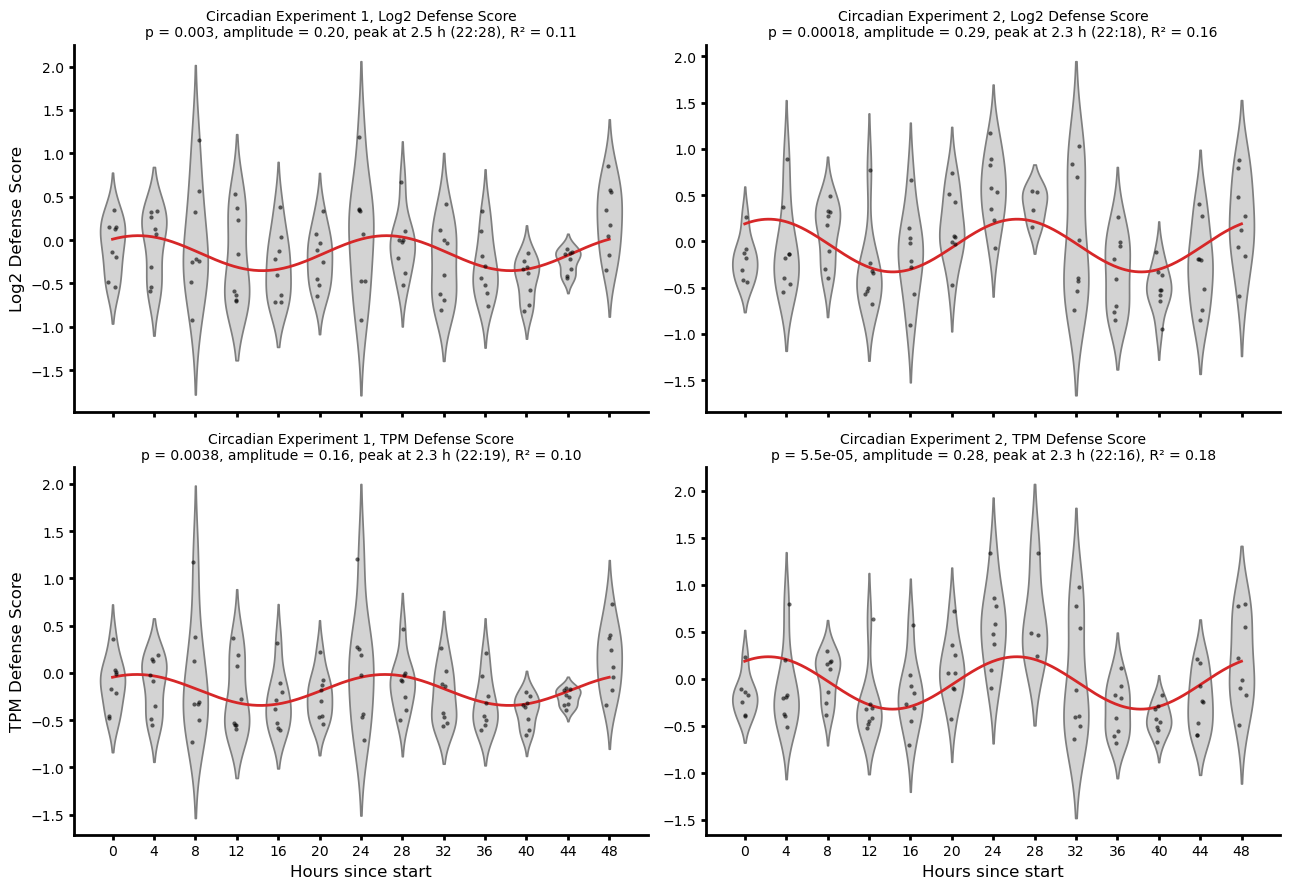

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
fig.patch.set_facecolor("white")
for row, score in enumerate(["Log2 Defense Score", "TPM Defense Score"]):
    for column, experiment in enumerate(experiments):
        ax = axes[row, column]
        part = circadian.loc[circadian["Experiment Type"] == experiment]
        sns.violinplot(
            data=part, x="Time Since Start", y=score, color="lightgray", inner=None, native_scale=True, width=0.6, density_norm="width", ax=ax,
        )
        sns.stripplot(data=part, x="Time Since Start", y=score, color="black", size=3, alpha=0.6, native_scale=True, ax=ax)
        grid, curve = curves[(score, experiment)]
        ax.plot(grid, curve, color="tab:red", linewidth=2)
        result = cosinor_results.loc[(cosinor_results["score"] == score) & (cosinor_results["experiment"] == experiment)].iloc[0]
        ax.set_title(
            f"{experiment}, {score}\n"
            f"p = {result['p']:.2g}, amplitude = {result['amplitude']:.2f}, peak at {result['acrophase[h]']:.1f} h ({result['peak (clock time)']}), R² = {result['R²']:.2f}",
            fontsize=10,
        )
        ax.set_xlabel("Hours since start" if row == 1 else "", fontsize=12)
        ax.set_ylabel(score if column == 0 else "", fontsize=12)
        ax.set_xticks(sorted(part["Time Since Start"].unique()))
        sns.despine(ax=ax)
        ax.spines["bottom"].set_color("black")
        ax.spines["bottom"].set_linewidth(2)
        ax.spines["left"].set_color("black")
        ax.spines["left"].set_linewidth(2)
        ax.tick_params(axis="both", width=2)
plt.tight_layout()

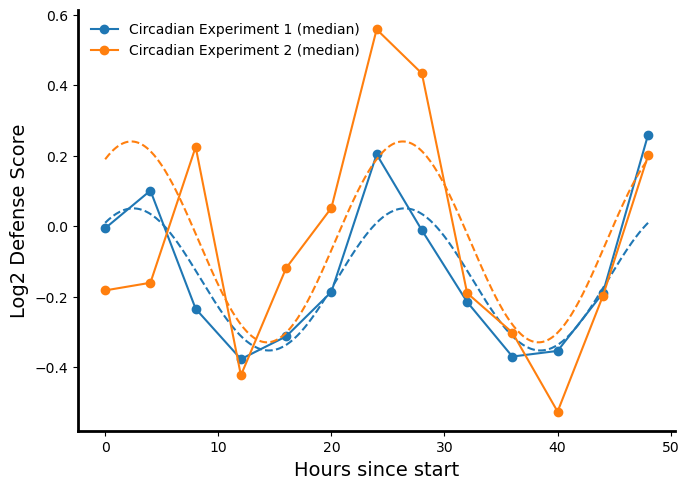

In [6]:
# Timepoint medians, as in the original scatter
fig, ax = plt.subplots(figsize=(7, 5))
fig.patch.set_facecolor("white")
for experiment, color in zip(experiments, ["tab:blue", "tab:orange"]):
    part = circadian.loc[circadian["Experiment Type"] == experiment]
    medians = part.groupby("Time Since Start")["Log2 Defense Score"].median()
    ax.plot(medians.index, medians.values, marker="o", color=color, label=f"{experiment} (median)")
    grid, curve = curves[("Log2 Defense Score", experiment)]
    ax.plot(grid, curve, color=color, linestyle="dashed", linewidth=1.5)
ax.set_xlabel("Hours since start", fontsize=14)
ax.set_ylabel("Log2 Defense Score", fontsize=14)
ax.legend(frameon=False)
sns.despine()
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_linewidth(2)
plt.tight_layout()

## Defense score vs bacterial load in the circadian samples

The original's load panels, with the log2 score and both experiments: load z-scored across all circadian samples, ranked across all samples, ranked within time of day, ranked within timepoint, and z-scored within time of day.

,experiment,load measure,n,r,R²,p
0,Circadian Experiment 1,Load Z Score (All Circadian Samples),103,0.0625,0.0039,0.5308
1,Circadian Experiment 1,Load Rank (All Circadian Samples),103,0.1049,0.0110,0.2916
2,Circadian Experiment 1,Load Rank Within Time of Day,103,0.2606,0.0679,0.0078
3,Circadian Experiment 1,Load Rank Within Timepoint,103,0.1122,0.0126,0.2593
4,Circadian Experiment 1,Load Z Score Within Time of Day,103,0.1626,0.0264,0.1007
5,Circadian Experiment 2,Load Z Score (All Circadian Samples),98,0.0530,0.0028,0.6045
6,Circadian Experiment 2,Load Rank (All Circadian Samples),98,0.0318,0.0010,0.7556
7,Circadian Experiment 2,Load Rank Within Time of Day,98,0.1609,0.0259,0.1134
8,Circadian Experiment 2,Load Rank Within Timepoint,98,0.0465,0.0022,0.6490
9,Circadian Experiment 2,Load Z Score Within Time of Day,98,0.1655,0.0274,0.1034


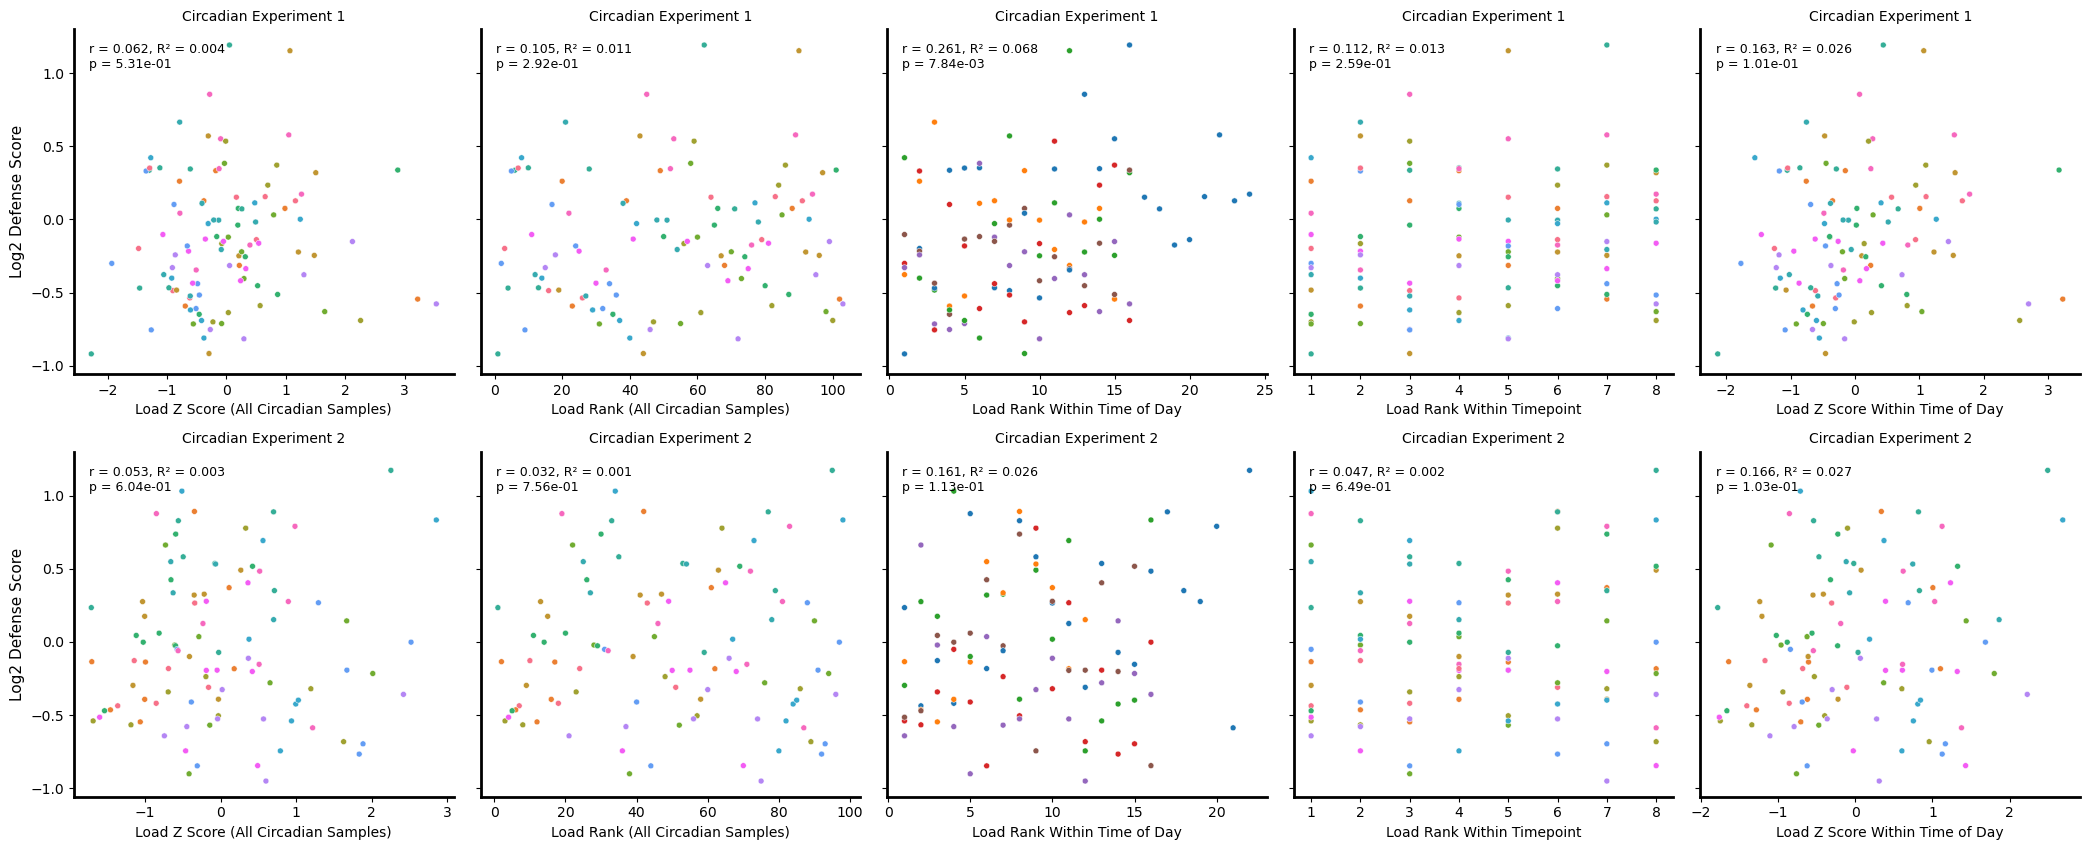

In [7]:
load_rows = []
circadian["ham16s_zscore"] = circadian.groupby("Experiment Type")["ham16s"].transform(lambda x: zscore(x, nan_policy="omit"))
circadian["Rank All Samples"] = circadian.groupby("Experiment Type")["ham16s"].rank()
circadian["Rank Within Time"] = circadian.groupby(["Experiment Type", "time"])["ham16s"].rank()
circadian["Rank Within Timepoint"] = circadian.groupby("timepoint")["ham16s"].rank()
circadian["ham16s_zscore_within_time"] = circadian.groupby(["Experiment Type", "time"])["ham16s"].transform(lambda x: zscore(x, nan_policy="omit"))
load_measures = {
    "ham16s_zscore": "Load Z Score (All Circadian Samples)",
    "Rank All Samples": "Load Rank (All Circadian Samples)",
    "Rank Within Time": "Load Rank Within Time of Day",
    "Rank Within Timepoint": "Load Rank Within Timepoint",
    "ham16s_zscore_within_time": "Load Z Score Within Time of Day",
}
fig, axes = plt.subplots(len(experiments), len(load_measures), figsize=(4.2 * len(load_measures), 4.3 * len(experiments)), sharey=True)
fig.patch.set_facecolor("white")
for row, experiment in enumerate(experiments):
    part = circadian.loc[circadian["Experiment Type"] == experiment]
    for column, (measure, label) in enumerate(load_measures.items()):
        ax = axes[row, column]
        hue = "time" if "Time" in measure and "Timepoint" not in measure else "timepoint"
        sns.scatterplot(data=part, x=measure, y="Log2 Defense Score", hue=hue, s=18, ax=ax, legend=False)
        valid = part[[measure, "Log2 Defense Score"]].dropna()
        r, p = pearsonr(valid[measure], valid["Log2 Defense Score"])
        load_rows.append({"experiment": experiment, "load measure": label, "n": len(valid), "r": r, "R²": r**2, "p": p})
        ax.text(0.04, 0.96, f"r = {r:.3f}, R² = {r**2:.3f}\np = {p:.2e}", transform=ax.transAxes, fontsize=9, va="top")
        ax.set_xlabel(label, fontsize=10)
        ax.set_ylabel("Log2 Defense Score" if column == 0 else "", fontsize=11)
        ax.set_title(experiment, fontsize=10)
        sns.despine(ax=ax)
        ax.spines["bottom"].set_linewidth(2)
        ax.spines["left"].set_linewidth(2)
plt.tight_layout()
pd.DataFrame(load_rows).round(4)